In [55]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [56]:
df = pd.read_csv("auto-mpg.csv")

In [57]:
df.shape

(398, 9)

In [58]:
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [59]:
df.drop("car name", axis=1, inplace=True)

In [60]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    object 
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   origin        398 non-null    int64  
dtypes: float64(3), int64(4), object(1)
memory usage: 25.0+ KB


In [61]:
df.isna().sum()

mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model year      0
origin          0
dtype: int64

In [62]:
df = df[df["horsepower"] != "?"]
print(df.shape)
df["horsepower"]=df["horsepower"].astype("int64")
print(df.head())
df = df.sample(frac=1, random_state=41).reset_index(drop=True)
print(df.head())

(392, 8)
    mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  18.0          8         307.0         130    3504          12.0   
1  15.0          8         350.0         165    3693          11.5   
2  18.0          8         318.0         150    3436          11.0   
3  16.0          8         304.0         150    3433          12.0   
4  17.0          8         302.0         140    3449          10.5   

   model year  origin  
0          70       1  
1          70       1  
2          70       1  
3          70       1  
4          70       1  
    mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  29.0          4         135.0          84    2525          16.0   
1  16.0          8         318.0         150    4498          14.5   
2  10.0          8         360.0         215    4615          14.0   
3  43.1          4          90.0          48    1985          21.5   
4  31.5          4          98.0          68    2045          18.5   

   mo

In [63]:
# Train Test split 80/20
train_size = int(0.8 * len(df))
df_train = df[:train_size]
df_test = df[train_size:]

In [64]:
X_train= df_train.iloc[:,1:]
print(X_train.head())
Y_train= df_train.iloc[:,0]
print(Y_train.head())

X_test= df_test.iloc[:,1:]
Y_test= df_test.iloc[:,0]

   cylinders  displacement  horsepower  weight  acceleration  model year  \
0          4         135.0          84    2525          16.0          82   
1          8         318.0         150    4498          14.5          75   
2          8         360.0         215    4615          14.0          70   
3          4          90.0          48    1985          21.5          78   
4          4          98.0          68    2045          18.5          77   

   origin  
0       1  
1       1  
2       1  
3       2  
4       3  
0    29.0
1    16.0
2    10.0
3    43.1
4    31.5
Name: mpg, dtype: float64


In [65]:
X_train_mu = np.array(X_train.mean())
X_train_std= np.array(X_train.std())

Y_train_mu = np.array(Y_train.mean())
Y_train_std= np.array(Y_train.std())

X_train = (X_train-X_train_mu)/X_train_std
Y_train = (Y_train-Y_train_mu)/Y_train_std

X_test = (X_test-X_train_mu)/X_train_std
Y_test = (Y_test-Y_train_mu)/Y_train_std


In [66]:
print(X_train.head())
print(Y_train.head())

   cylinders  displacement  horsepower    weight  acceleration  model year  \
0  -0.857877     -0.567898   -0.524555 -0.539508      0.148119    1.590073   
1   1.492367      1.214835    1.202338  1.824627     -0.380717   -0.294108   
2   1.492367      1.623987    2.903066  1.964821     -0.556996   -1.639951   
3  -0.857877     -1.006275   -1.466496 -1.186560      2.087185    0.513398   
4  -0.857877     -0.928341   -0.943195 -1.114665      1.029513    0.244230   

     origin  
0 -0.707577  
1 -0.707577  
2 -0.707577  
3  0.550784  
4  1.809146  
0    0.688790
1   -0.956268
2   -1.715526
3    2.473045
4    1.005147
Name: mpg, dtype: float64


Linear Regression

In [67]:
m=X_train.shape[0]
n=X_train.shape[1]

In [68]:
w=np.zeros(n)
b=0

# Cost function (MSE) J_wb
def J_wb(X,w,b,y):
    m=X.shape[0]
    predictions = (X @ w) + b # (m x n @ n x 1) = (m x 1)
    cost = (1/(2*m))* np.sum((predictions-y)**2)
    return cost

# gradient_descent_algorithm
def fit_via_gd(X,w,b,y,alpha=0.0001,epsilon=0.0001,max_epochs=1e5):
    m=X.shape[0]
    cost_history=[]
    prev_cost = float('inf')

    for i in range(max_epochs):
        
        predictions=X @ w + b   # (m x n @ n x 1) = (m x 1)
        error=predictions-y     # (m x 1)
        dw=(1/m)*(X.T @ error)  # (n x m @ m x 1) = (n x 1) 
        db=(1/m)* np.sum(error) # np.sum(m x 1) = 1 x 1
        w= w - (alpha * dw)     # (n x 1)
        b= b - (alpha * db)     # 1 x 1

        curr_cost = J_wb(X, w, b , y)
        cost_history.append(curr_cost)

        if abs(curr_cost - prev_cost)<epsilon:
            print("Cost frunction is converged at epoch-", i, " with final cost = ", curr_cost, " bcoz the cost is not updating >= epsilon")
            break
        if i==max_epochs-1:
            print("Cost frunction is converged at epoch-", max_epochs, " with final cost = ", curr_cost, " bcoz max epochs reached")
            break

        prev_cost= curr_cost

        # Update live plot every 10 epochs
        if i % 10000 == 0:
            print("Epoch no.: ",i, ", Current Cost: ",curr_cost)


    return w,b,cost_history




In [69]:
w_final, b_final, costhistory = fit_via_gd(X_train,w,b,Y_train,alpha=0.0001,epsilon=1e-7,max_epochs=int(1e5))
print("Final weights:", w_final)
print("Final bias:", b_final)


Epoch no.:  0 , Current Cost:  0.49807330400337
Epoch no.:  10000 , Current Cost:  0.1151066290850631
Epoch no.:  20000 , Current Cost:  0.10705612783775295
Epoch no.:  30000 , Current Cost:  0.10392934767127104
Epoch no.:  40000 , Current Cost:  0.1021547246731579
Epoch no.:  50000 , Current Cost:  0.10087844767282059
Cost frunction is converged at epoch- 55529  with final cost =  0.10029237887940573  bcoz the cost is not updating >= epsilon
Final weights: cylinders      -0.071696
displacement   -0.069676
horsepower     -0.169724
weight         -0.352749
acceleration   -0.037841
model year      0.334686
origin          0.138855
dtype: float64
Final bias: -3.3415904051624913e-16


In [70]:
Y_predctions = X_test @ w_final + b_final
Y_pred_real = (Y_predctions * Y_train_std) + Y_train_mu
Y_test_real = (Y_test * Y_train_std) + Y_train_mu
new_df = pd.DataFrame({
    "Predicted MPG": Y_pred_real,
    "Actual MPG": Y_test_real
})
new_df


,Predicted MPG,Actual MPG
313,19.075358,19.4
314,18.547391,18.5
315,10.290868,12.0
316,19.039143,22.0
317,23.346028,23.0
...,...,...
387,22.898834,20.6
388,8.999192,12.0
389,30.520709,36.1
390,26.924566,27.9


In [71]:
rmse = np.sqrt(np.mean((Y_pred_real - Y_test_real)**2))
mae = np.mean(np.abs(Y_pred_real - Y_test_real))
print("RMSE: ", rmse)
print("MAE: ", mae)


RMSE:  2.808786993064623
MAE:  2.2248043384287874


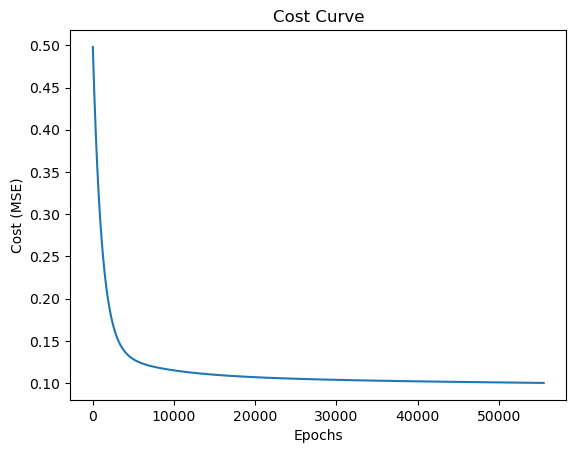

In [72]:
plt.plot(costhistory)
plt.xlabel("Epochs")
plt.ylabel("Cost (MSE)")
plt.title("Cost Curve")
plt.show()

